# Does the perturbation that minimizes P2H also minimize predicted PANSS?

`panss_model_region_overfit.ipynb` found that a fixed matrix-element subset + `RidgeCV`
on the **Ftau** (lag-1 functional connectivity) matrix was the best-performing PANSS
model (`R2 ~ 0.31`, `corr(y, yhat) ~ 0.56` at `threshold=0.2`). Separately,
`gec_matrices.ipynb` computes, for every subject and every candidate perturbation node,
a **P2H** score (how much a local noise perturbation at that node shifts the subject's
simulated FC toward/away from the healthy-group mean FC) and a **P2O** score.

This notebook connects the two: it feeds the *simulated, perturbed* Ftau matrix
(`simulate_perturbed_fs`, the FS analogue of `simulate_perturbed_fc` added to
`gec_matrices.ipynb`) through the fitted Ftau+Ridge PANSS model, for every candidate
perturbation node, in every subject. This gives a "predicted PANSS under perturbation
at node *j*" curve across all 100 regions, per subject -- which can then be compared
directly against that subject's P2H (and P2O) map.

**Hypothesis under test:** the node that minimizes P2H (the perturbation that best
resists/steers away from... see caveat below) is the same node that minimizes
predicted PANSS (i.e. the model "believes" that perturbation would help the most).

**Caveat on delta_sigma:** `compute_p2h_map` in `gec_matrices.ipynb` uses
`delta_sigma=0.1`. The function that generated the saved `p2o_maps.pkl` is no longer
present in any notebook in this repo (only its serialized output survives), so its
`delta_sigma` cannot be confirmed -- this notebook assumes `delta_sigma=0.1` to match
`p2h` for consistency. If P2O was in fact generated with a different perturbation
strength, the P2O comparisons below should be treated as approximate.

**Avoiding a training-PANSS-of-the-subject-itself leak:** predicting a subject's PANSS
under its own perturbations with a model that was *trained on that subject's true
score* would be circular. So for each subject, its "predicted PANSS under perturbation"
curve uses a `RidgeCV` fit on every *other* subject only (the same model each subject
gets scored by in the overfit notebook's LOOCV) -- feature selection (which matrix
elements are used) is still the fixed, full-sample selection, consistent with the rest
of this repo's design.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.linalg as la
from scipy.signal import welch
from scipy.stats import pearsonr, spearmanr, ttest_1samp
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from joblib import Parallel, delayed

## Load data

In [2]:
# GEC (per-subject effective connectivity)
study_results = np.load("./data/study_results.pkl", allow_pickle=True)

# fmri timeseries
fmri = np.load('./data/HCP_early_psychosis_timeseries_cleaned.npz')
ts_ap = fmri['ts_ap']
ts_nap = fmri['ts_nap']

# clinical scores
clinical = np.load('./data/HCP_early_psychosis_clinical_scores.npz')
panss_AP = clinical["panss_AP"]
panss_NAP = clinical["panss_NAP"]

# Perturbability maps: per-region (100,) scores per subject, keyed by group then subject index
p2h_maps = np.load("./data/p2h_maps.pkl", allow_pickle=True)
p2o_maps = np.load("./data/p2o_maps.pkl", allow_pickle=True)
p2h_raw_maps = np.load("./data/p2h_raw_maps.pkl", allow_pickle=True)

# Model constants, matching gec_matrices.ipynb
TR = 2.0
SIGMA = 0.01
DELTA_SIGMA = 0.1  # matches compute_p2h_map's default; assumed for p2o too, see intro caveat

## Shared helpers

Self-contained (same convention as `perturbability_model_performance.ipynb`):
Ftau/off-diagonal feature helpers and the fixed-selection + Ridge LOOCV pipeline from
`panss_model_region_overfit.ipynb`, plus `simulate_perturbed_fs` and
`estimate_intrinsic_frequencies` from `gec_matrices.ipynb`.

In [3]:
def compute_ftau_matrix(sub_ts, tau=1):
    """Lag-tau (empirical) functional connectivity matrix."""
    n_regions = sub_ts.shape[0]
    ts_t0 = sub_ts[:, :-tau]
    ts_ttau = sub_ts[:, tau:]
    full_corr = np.corrcoef(ts_t0, ts_ttau)
    return full_corr[:n_regions, n_regions:]


def offdiag_mask(n):
    """Boolean mask selecting every off-diagonal position of an n x n matrix."""
    return ~np.eye(n, dtype=bool)


def flatten_offdiag_features(matrix):
    """Every off-diagonal element of the connectivity matrix, flattened to one feature vector."""
    mat = np.nan_to_num(matrix)
    return mat[offdiag_mask(mat.shape[0])]


def estimate_intrinsic_frequencies(ts, TR, band=(0.008, 0.08)):
    """Peak PSD frequency per region within `band`, via Welch's method (from gec_matrices.ipynb)."""
    N, T = ts.shape
    fs = 1.0 / TR
    f_diff = np.zeros(N)
    freqs, psd = welch(ts, fs=fs, nperseg=min(T, 512))
    idx_band = np.where((freqs >= band[0]) & (freqs <= band[1]))[0]
    for i in range(N):
        peak_idx = idx_band[np.argmax(psd[i, idx_band])]
        f_diff[i] = freqs[peak_idx]
    return f_diff


def simulate_perturbed_fs(GEC, f_diff, sigma, node_idx, delta_sigma, TR, tau=1):
    """
    Lag-tau (FS) connectivity matrix under a local noise perturbation at
    node_idx -- the FS analogue of simulate_perturbed_fc (gec_matrices.ipynb):
    same perturbed noise covariance, but the stationary covariance is
    propagated forward by tau*TR (matrix exponential of the Jacobian) before
    normalizing, matching how FSsim is derived from COVsim in estimate_gec.
    """
    N = GEC.shape[0]
    a, Jxy = -0.02, np.diag(f_diff)
    Jxx = np.diag(a - np.sum(GEC, axis=1)) + GEC
    A = np.block([[Jxx, Jxy], [-Jxy, Jxx]])

    Q = (sigma**2) * np.eye(2 * N)
    Q[node_idx, node_idx] += delta_sigma**2
    Q[node_idx + N, node_idx + N] += delta_sigma**2

    K_p = la.solve_continuous_lyapunov(A, -Q)

    matrix_exp = la.expm((tau * TR) * A)
    cov_tau_raw = (matrix_exp @ K_p)[:N, :N]

    diag_zero_lag = np.diag(K_p[:N, :N]).copy()
    diag_zero_lag[diag_zero_lag <= 0] = 1e-12
    std_inv = 1.0 / np.sqrt(diag_zero_lag)
    return cov_tau_raw * np.outer(std_inv, std_inv)


def select_fixed_features(X, y, threshold):
    """Full-sample correlation-threshold feature selection (same as the overfit notebook)."""
    corrs = np.array([pearsonr(X[:, j], y)[0] for j in range(X.shape[1])])
    corrs = np.nan_to_num(corrs)
    selected = np.where(np.abs(corrs) > threshold)[0]
    if selected.size == 0:
        selected = np.array([np.argmax(np.abs(corrs))])
    return selected


def run_ridge_loocv(X, y):
    """RidgeCV evaluated by LOOCV: refit per fold on the training subjects, predict the held-out subject."""
    loo = LeaveOneOut()
    y_true_all, y_pred_all = [], []
    for train_index, test_index in loo.split(X):
        model = RidgeCV(alphas=np.logspace(-3, 3, 13))
        model.fit(X[train_index], y[train_index])
        pred = model.predict(X[test_index])
        y_true_all.append(y[test_index][0])
        y_pred_all.append(pred[0])
    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    corr, pval = pearsonr(y_true_all, y_pred_all)
    return {
        "y_true": y_true_all, "y_pred": y_pred_all,
        "rmse": np.sqrt(mean_squared_error(y_true_all, y_pred_all)),
        "mae": mean_absolute_error(y_true_all, y_pred_all),
        "r2": r2_score(y_true_all, y_pred_all),
        "corr": corr, "pval": pval,
    }

## Build the pooled, aligned dataset

Pools AP-then-NAP, keeps only subjects with a valid PANSS score -- same ordering
convention as `perturbability_model_performance.ipynb` -- and keeps each subject's GEC
matrix, raw timeseries, full P2H/P2O maps (not just their `max`/`min`) all aligned by
that same ordering, since the perturbation sweep below needs the GEC + timeseries per
subject, not just their Ftau matrix.

In [4]:
subjects = []
for group, ts_array, panss in (("AP", ts_ap, panss_AP), ("NAP", ts_nap, panss_NAP)):
    for idx in range(ts_array.shape[0]):
        if np.isnan(panss[idx]):
            continue
        subjects.append({
            "group": group, "idx": idx,
            "ts": ts_array[idx, :, :],
            "gec": study_results[group][idx]["GEC_matrix"].astype(np.float64),
            "panss": panss[idx],
            "p2h": p2h_maps[group][idx],
            "p2o": p2o_maps[group][idx],
            "p2h_raw": p2h_raw_maps[group][idx],
        })

print(f"N subjects (pooled, valid PANSS) = {len(subjects)}")

X = np.array([flatten_offdiag_features(compute_ftau_matrix(s["ts"], tau=1)) for s in subjects])
y = np.array([s["panss"] for s in subjects])
p2h_full = np.array([s["p2h"] for s in subjects])  # (n_subjects, 100)
p2o_full = np.array([s["p2o"] for s in subjects])  # (n_subjects, 100)
p2h_raw_full = np.array([s["p2h_raw"] for s in subjects])  # (n_subjects, 100)

N subjects (pooled, valid PANSS) = 92


## Fixed feature selection + baseline LOOCV

Same fixed Ftau + Ridge pipeline as `panss_model_region_overfit.ipynb` at
`threshold=0.2` -- the best-performing model there. `selected_idx` (which matrix
elements the perturbation-scoring model reads) and `baseline_loocv` (the unperturbed
LOOCV predictions, for the sanity check two cells down) are both reused below.

Selected 233 / 9900 matrix elements
Baseline LOOCV R2   = 0.3142
Baseline LOOCV corr = 0.5644  (p=4.64e-09)


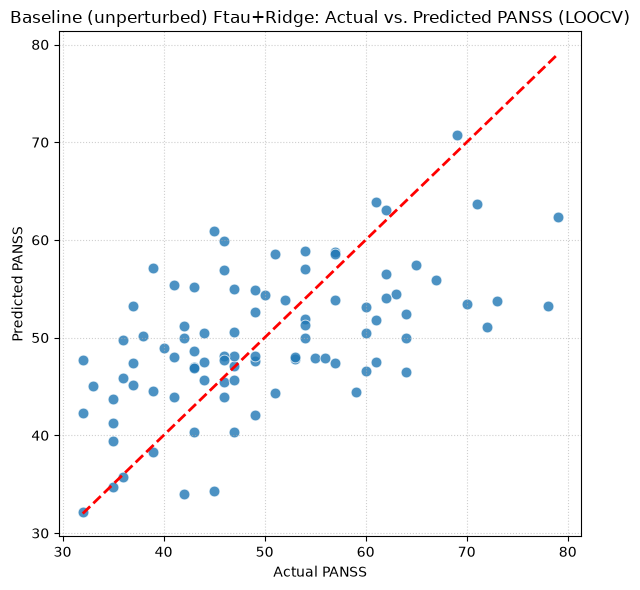

In [5]:
selected_idx = select_fixed_features(X, y, threshold=0.2)
X_sel = X[:, selected_idx]

baseline_loocv = run_ridge_loocv(X_sel, y)
print(f"Selected {len(selected_idx)} / {X.shape[1]} matrix elements")
print(f"Baseline LOOCV R2   = {baseline_loocv['r2']:.4f}")
print(f"Baseline LOOCV corr = {baseline_loocv['corr']:.4f}  (p={baseline_loocv['pval']:.4g})")

plt.figure(figsize=(6, 6))
sns.scatterplot(x=baseline_loocv["y_true"], y=baseline_loocv["y_pred"], color='#1f77b4', s=60, alpha=0.8)
min_val = min(baseline_loocv["y_true"].min(), baseline_loocv["y_pred"].min())
max_val = max(baseline_loocv["y_true"].max(), baseline_loocv["y_pred"].max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
plt.title('Baseline (unperturbed) Ftau+Ridge: Actual vs. Predicted PANSS (LOOCV)')
plt.xlabel('Actual PANSS')
plt.ylabel('Predicted PANSS')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## Perturbation sweep: simulate every candidate node, every subject

For each subject, `simulate_perturbed_fs` is called once per candidate node (100 calls),
using that subject's own GEC matrix and intrinsic frequencies. The Jacobian `A` depends
only on GEC/frequencies (not on which node is perturbed), so this is embarrassingly
parallel across subjects -- `joblib` spreads the 92 subjects (9200 simulations total)
across CPU cores.

In [6]:
def process_subject(gec, ts):
    """All 100 candidate-node perturbed Ftau (FS) matrices for one subject, as offdiag feature rows."""
    N = gec.shape[0]
    f_diff = estimate_intrinsic_frequencies(ts, TR)
    mask = offdiag_mask(N)
    feats = np.zeros((N, mask.sum()))
    for j in range(N):
        fs_pert = simulate_perturbed_fs(gec, f_diff, SIGMA, j, DELTA_SIGMA, TR, tau=1)
        feats[j] = np.nan_to_num(fs_pert)[mask]
    return feats


t0 = time.time()
perturbed_feats = Parallel(n_jobs=-1)(delayed(process_subject)(s["gec"], s["ts"]) for s in subjects)
perturbed_feats = np.array(perturbed_feats)  # (n_subjects, 100, n_edges_total)
perturbed_feats_sel = perturbed_feats[:, :, selected_idx]  # (n_subjects, 100, n_selected)
print(f"Perturbation sweep: {perturbed_feats.shape[0]} subjects x {perturbed_feats.shape[1]} nodes "
      f"in {time.time() - t0:.1f}s")

Perturbation sweep: 92 subjects x 100 nodes in 72.1s


## Predicted PANSS at every candidate perturbation

For each subject, `RidgeCV` is refit on every *other* subject (same fixed
`selected_idx`), then used to score: (a) that subject's own unperturbed Ftau -- which
must reproduce `baseline_loocv["y_pred"]` exactly, since this is the same LOOCV fold --
and (b) all 100 perturbed Ftau matrices, giving `node_preds[i, j]` = predicted PANSS for
subject *i* under a perturbation at node *j*.

In [7]:
n_subjects = X_sel.shape[0]
node_preds = np.zeros((n_subjects, 100))
baseline_preds_check = np.zeros(n_subjects)

for i in range(n_subjects):
    train_mask = np.ones(n_subjects, dtype=bool)
    train_mask[i] = False
    model = RidgeCV(alphas=np.logspace(-3, 3, 13))
    model.fit(X_sel[train_mask], y[train_mask])
    baseline_preds_check[i] = model.predict(X_sel[i].reshape(1, -1))[0]
    node_preds[i] = model.predict(perturbed_feats_sel[i])

max_diff = np.max(np.abs(baseline_preds_check - baseline_loocv["y_pred"]))
print(f"Sanity check -- max |per-subject LOOCV-fold baseline pred - baseline_loocv y_pred| = {max_diff:.2e}")
assert max_diff < 1e-6, "per-subject LOOCV-fold models should reproduce baseline_loocv exactly"

Sanity check -- max |per-subject LOOCV-fold baseline pred - baseline_loocv y_pred| = 1.42e-14


## Hypothesis test: same node minimizing P2H and predicted PANSS?

Two versions, from strict to lenient:
1. **Exact match**: does `argmin_j(node_preds[i, j])` equal `argmin_j(p2h[i, j])`?
2. **Rank position**: where does the P2H-minimizing node fall within that subject's
   predicted-PANSS ordering (rank 1 = the node predicted-PANSS actually picks as best)?
   Under the null (no relationship) the expected rank is `50.5`; a mean significantly
   *below* that says the P2H-favored node tends to also look relatively good to the
   PANSS model, even without being the single best pick. The same check is run for the
   node that *maximizes* P2O.

In [8]:
argmin_panss_node = np.argmin(node_preds, axis=1)
argmin_p2h_node = np.argmin(p2h_full, axis=1)
argmax_p2o_node = np.argmax(p2o_full, axis=1)

match_rate = np.mean(argmin_panss_node == argmin_p2h_node)
print(f"Exact argmin match rate (panss-minimizing node == p2h-minimizing node): "
      f"{match_rate:.4f}  (n={n_subjects}, chance = 1/100 = 0.01)")

ranks_p2h, ranks_p2o = [], []
for i in range(n_subjects):
    order = np.argsort(node_preds[i])  # ascending: rank 1 = lowest (best) predicted PANSS
    ranks_p2h.append(int(np.where(order == argmin_p2h_node[i])[0][0]) + 1)
    ranks_p2o.append(int(np.where(order == argmax_p2o_node[i])[0][0]) + 1)
ranks_p2h = np.array(ranks_p2h)
ranks_p2o = np.array(ranks_p2o)

t_p2h = ttest_1samp(ranks_p2h, 50.5)
t_p2o = ttest_1samp(ranks_p2o, 50.5)
print(f"\nRank (in ascending predicted-PANSS order) of the P2H-minimizing node: "
      f"mean={ranks_p2h.mean():.1f} (null=50.5), t={t_p2h.statistic:.3f}, p={t_p2h.pvalue:.4f}")
print(f"Rank (in ascending predicted-PANSS order) of the P2O-maximizing node: "
      f"mean={ranks_p2o.mean():.1f} (null=50.5), t={t_p2o.statistic:.3f}, p={t_p2o.pvalue:.4f}")

Exact argmin match rate (panss-minimizing node == p2h-minimizing node): 0.0000  (n=92, chance = 1/100 = 0.01)

Rank (in ascending predicted-PANSS order) of the P2H-minimizing node: mean=44.7 (null=50.5), t=-3.001, p=0.0035
Rank (in ascending predicted-PANSS order) of the P2O-maximizing node: mean=48.4 (null=50.5), t=-0.591, p=0.5557


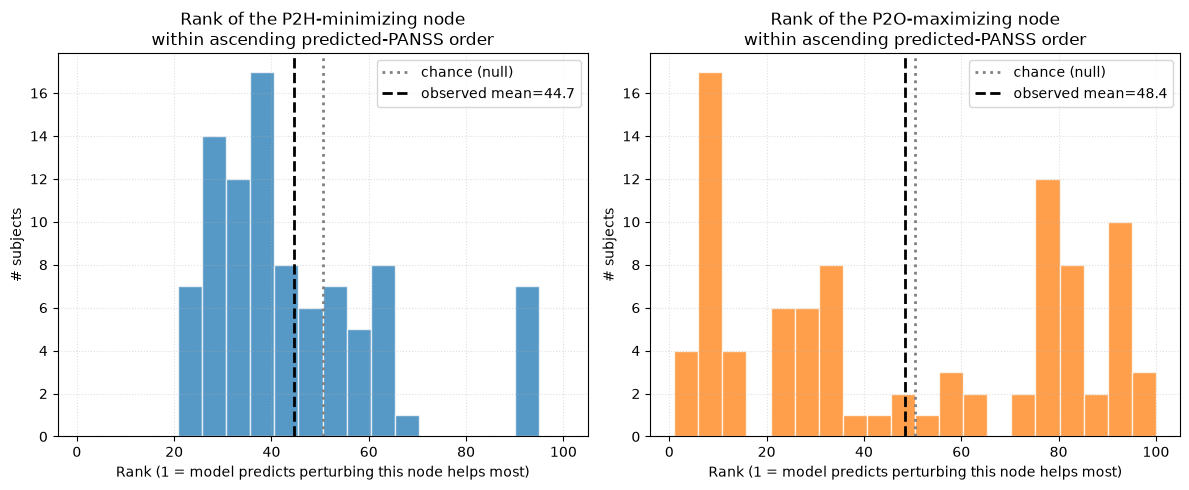

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, ranks, label, color in (
    (axes[0], ranks_p2h, "P2H-minimizing node", "#1f77b4"),
    (axes[1], ranks_p2o, "P2O-maximizing node", "#ff7f0e"),
):
    ax.hist(ranks, bins=20, range=(1, 100), color=color, alpha=0.75, edgecolor='white')
    ax.axvline(50.5, color='gray', linestyle=':', linewidth=2, label='chance (null)')
    ax.axvline(ranks.mean(), color='black', linestyle='--', linewidth=2, label=f'observed mean={ranks.mean():.1f}')
    ax.set_title(f'Rank of the {label}\nwithin ascending predicted-PANSS order')
    ax.set_xlabel('Rank (1 = model predicts perturbing this node helps most)')
    ax.set_ylabel('# subjects')
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

## Per-subject correlation: predicted-PANSS-under-perturbation vs. P2H / P2O

For each subject, correlates the 100-node `node_preds[i, :]` curve against that
subject's own `p2h[i, :]` and `p2o[i, :]` maps (Spearman, since neither quantity is
assumed linear in node identity). This is the node-level, within-subject version of
"does perturbability track predicted PANSS" -- distinct from (and a finer-grained
complement to) the single-node hypothesis test above.

Per-subject Spearman(node_preds, p2h): mean=0.0477 (sd=0.0738), t=6.167, p=1.889e-08
Per-subject Spearman(node_preds, p2o): mean=-0.1556 (sd=0.0801), t=-18.524, p=1.247e-32


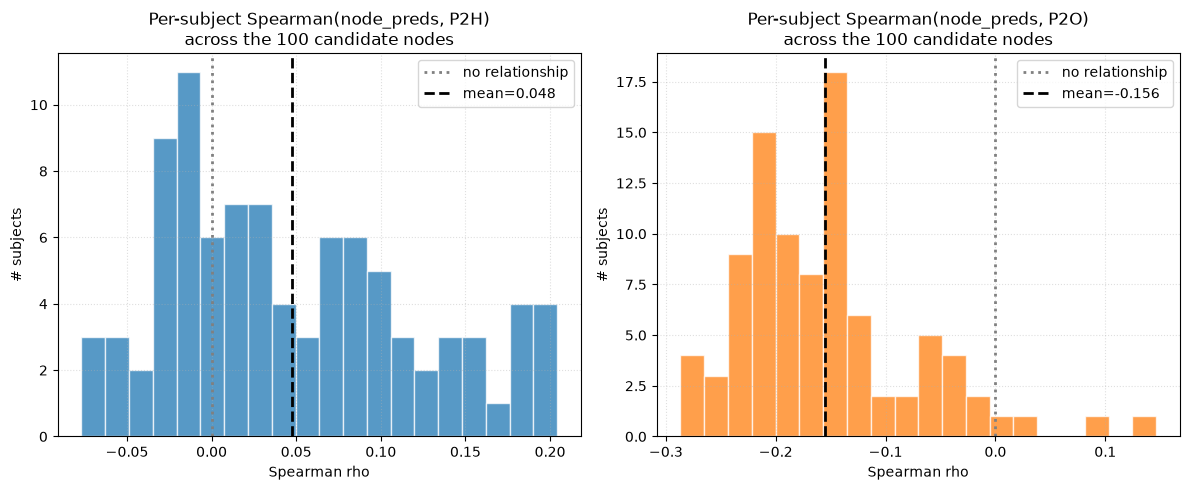

In [10]:
rhos_p2h, rhos_p2o = [], []
for i in range(n_subjects):
    rho_h, _ = spearmanr(node_preds[i], p2h_full[i])
    rho_o, _ = spearmanr(node_preds[i], p2o_full[i])
    rhos_p2h.append(rho_h)
    rhos_p2o.append(rho_o)
rhos_p2h = np.array(rhos_p2h)
rhos_p2o = np.array(rhos_p2o)

t_rho_h = ttest_1samp(rhos_p2h, 0.0)
t_rho_o = ttest_1samp(rhos_p2o, 0.0)
print(f"Per-subject Spearman(node_preds, p2h): mean={rhos_p2h.mean():.4f} (sd={rhos_p2h.std():.4f}), "
      f"t={t_rho_h.statistic:.3f}, p={t_rho_h.pvalue:.4g}")
print(f"Per-subject Spearman(node_preds, p2o): mean={rhos_p2o.mean():.4f} (sd={rhos_p2o.std():.4f}), "
      f"t={t_rho_o.statistic:.3f}, p={t_rho_o.pvalue:.4g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, rhos, label, color in (
    (axes[0], rhos_p2h, "P2H", "#1f77b4"),
    (axes[1], rhos_p2o, "P2O", "#ff7f0e"),
):
    ax.hist(rhos, bins=20, color=color, alpha=0.75, edgecolor='white')
    ax.axvline(0, color='gray', linestyle=':', linewidth=2, label='no relationship')
    ax.axvline(rhos.mean(), color='black', linestyle='--', linewidth=2, label=f'mean={rhos.mean():.3f}')
    ax.set_title(f'Per-subject Spearman(node_preds, {label})\nacross the 100 candidate nodes')
    ax.set_xlabel('Spearman rho')
    ax.set_ylabel('# subjects')
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

## Pooled correlation: predicted PANSS vs. P2H / P2O

Pools all `n_subjects x 100` node-perturbation pairs directly: `node_preds.ravel()`
against `p2h_full.ravel()` / `p2o_full.ravel()`. Note this mixes between-subject
variation (sicker subjects tend to differ from milder ones on both axes) together with
the node-to-node, within-subject variation the hypothesis is actually about -- the
per-subject Spearman correlations above are the cleaner within-subject read; this is
the plain pooled view.

Pooled corr(node_preds, p2h) = -0.2547  (p=3.23e-136)
Pooled corr(node_preds, p2o) = +0.2609  (p=4.64e-143)
Pooled corr(node_preds, p2h_raw) = -0.0760  (p=2.82e-13)


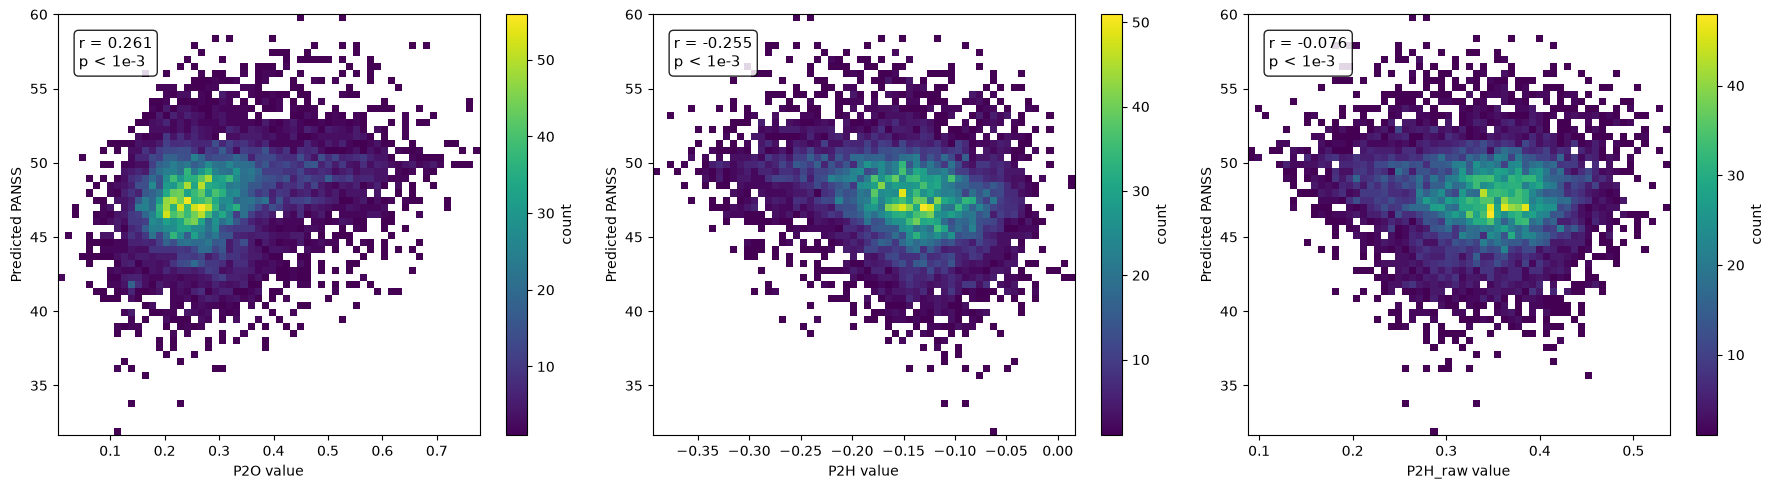

In [11]:
r_h_raw, p_h_raw = pearsonr(node_preds.ravel(), p2h_full.ravel())
r_o_raw, p_o_raw = pearsonr(node_preds.ravel(), p2o_full.ravel())
r_hraw_raw, p_hraw_raw = pearsonr(node_preds.ravel(), p2h_raw_full.ravel())

print(f"Pooled corr(node_preds, p2h) = {r_h_raw:+.4f}  (p={p_h_raw:.3g})")
print(f"Pooled corr(node_preds, p2o) = {r_o_raw:+.4f}  (p={p_o_raw:.3g})")
print(f"Pooled corr(node_preds, p2h_raw) = {r_hraw_raw:+.4f}  (p={p_hraw_raw:.3g})")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [
    (axes[0], p2o_full.ravel(), node_preds.ravel(), "P2O", r_o_raw, p_o_raw),
    (axes[1], p2h_full.ravel(), node_preds.ravel(), "P2H", r_h_raw, p_h_raw),
    (axes[2], p2h_raw_full.ravel(), node_preds.ravel(), "P2H_raw", r_hraw_raw, p_hraw_raw),
]

for ax, xvals, yvals, label, r_val, p_val in panels:
    h = ax.hist2d(xvals, yvals, bins=60, cmap="viridis", cmin=1)
    fig.colorbar(h[3], ax=ax, label='count')
    p_str = "p < 1e-3" if p_val < 1e-3 else f"p = {p_val:.3f}"
    ax.text(0.05, 0.95, f"r = {r_val:.3f}\n{p_str}", transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))
    ax.set_xlabel(f'{label} value')
    ax.set_ylabel('Predicted PANSS')

plt.tight_layout()
plt.show()

## Which regions dominate, across the whole cohort?

`argmin_panss_node[i]`, `argmax_p2o_node[i]`, and `argmin_p2h_node[i]` (computed in the
hypothesis-test section above) each reduce one subject to a single "winning" region --
the one perturbation that minimizes predicted PANSS, maximizes P2O, or minimizes P2H
for that subject. Everything so far compared these on a *per-subject* basis. This asks
a cohort-level question instead: forgetting which subject picked what, which specific
regions get picked most often as the PANSS-minimizing perturbation across all 92
subjects -- and does that list resemble the regions most often picked as the most
"perturbable" (highest P2O, most negative P2H, i.e. the largest-magnitude shifts either
way)?

In [12]:
N_REGIONS = 100

counts_panss = np.bincount(argmin_panss_node, minlength=N_REGIONS)
counts_p2o = np.bincount(argmax_p2o_node, minlength=N_REGIONS)
counts_p2h = np.bincount(argmin_p2h_node, minlength=N_REGIONS)


def top_regions(counts, k=10):
    """Regions ranked by how often they are the 'winning' node, as (region, count) pairs."""
    order = np.argsort(counts)[::-1]
    return [(int(r), int(counts[r])) for r in order[:k] if counts[r] > 0]


print("Top regions -- minimizes predicted PANSS:", top_regions(counts_panss))
print("Top regions -- maximizes P2O:            ", top_regions(counts_p2o))
print("Top regions -- minimizes P2H:            ", top_regions(counts_p2h))

Top regions -- minimizes predicted PANSS: [(63, 63), (29, 28), (60, 1)]
Top regions -- maximizes P2O:             [(8, 24), (36, 21), (76, 11), (86, 10), (59, 9), (26, 6), (92, 4), (69, 4), (68, 2), (13, 1)]
Top regions -- minimizes P2H:             [(26, 78), (69, 7), (93, 5), (65, 2)]


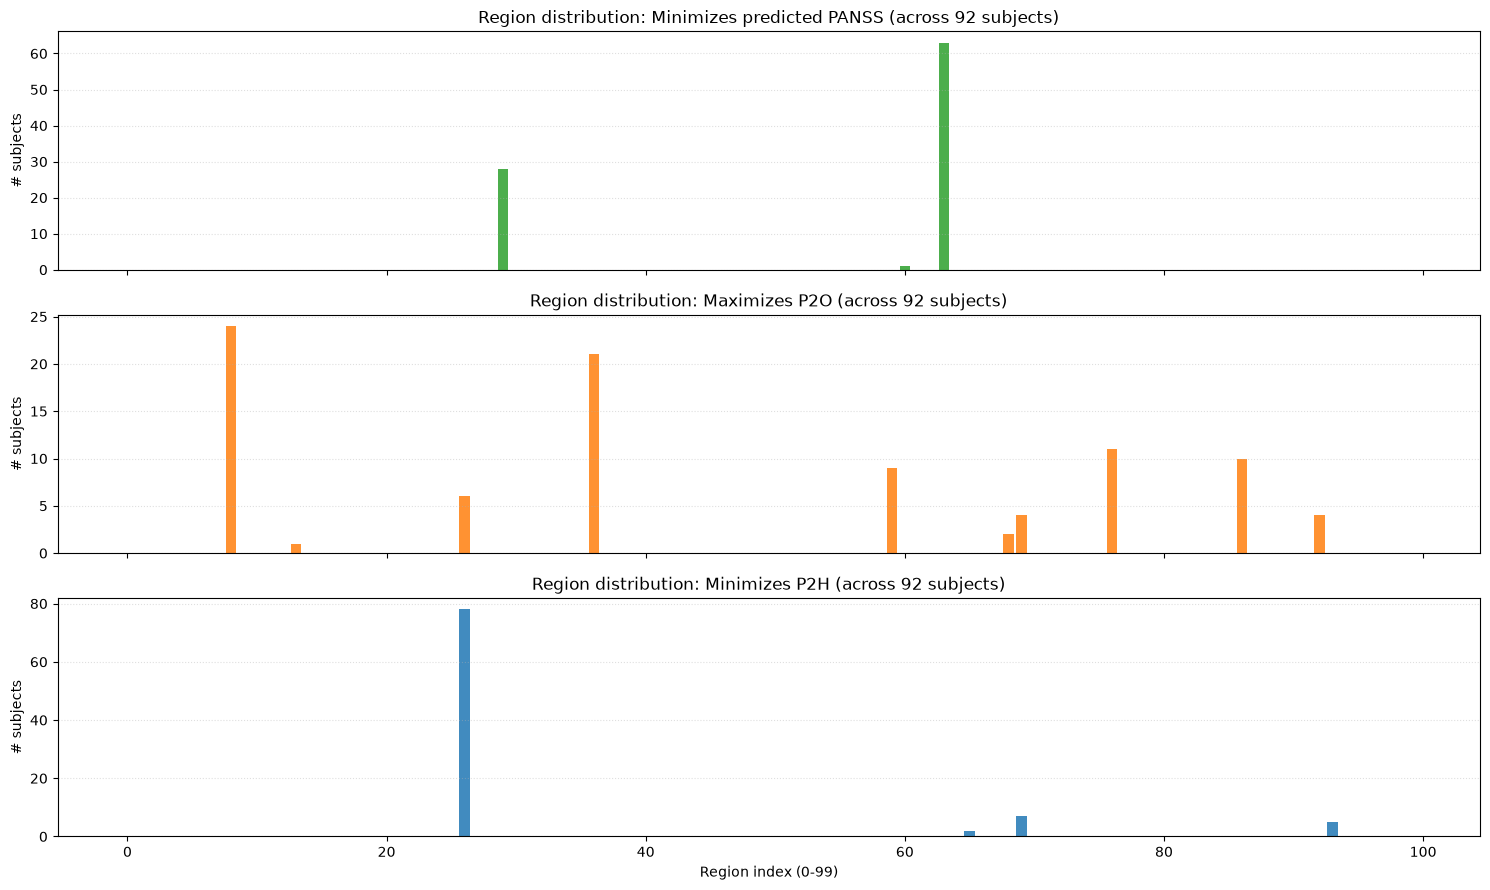

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)

for ax, counts, label, color in (
    (axes[0], counts_panss, "Minimizes predicted PANSS", "#2ca02c"),
    (axes[1], counts_p2o, "Maximizes P2O", "#ff7f0e"),
    (axes[2], counts_p2h, "Minimizes P2H", "#1f77b4"),
):
    ax.bar(range(N_REGIONS), counts, color=color, alpha=0.85)
    ax.set_title(f'Region distribution: {label} (across {n_subjects} subjects)')
    ax.set_ylabel('# subjects')
    ax.grid(True, axis='y', linestyle=':', alpha=0.4)

axes[-1].set_xlabel('Region index (0-99)')
plt.tight_layout()
plt.show()

**Comparing the two sets of regions.** A simpler complement to the per-subject rank
test above: instead of asking "for this subject, is the P2H/P2O node ranked well by
the PANSS model," ask "across the cohort, is a region that's frequently the
PANSS-minimizer also frequently a P2O/P2H extremum" -- via (a) the Spearman correlation
between the two 100-region count vectors, and (b) the overlap between each list's
top-10 most-picked regions.

Correlation between per-region counts:
  panss-min vs p2o-max: rho=-0.0585 (p=0.563)   r=-0.0343 (p=0.735)
  panss-min vs p2h-min: rho=-0.0359 (p=0.723)   r=-0.0159 (p=0.875)
  p2o-max   vs p2h-min: rho=+0.2698 (p=0.00664)   r=+0.1459 (p=0.147)

(Note: 3/10, 10/10, 4/10 slots filled for panss-min/p2o-max/p2h-min respectively -- fewer than K means that few regions ever won at all.)

Top-10 region overlap (Jaccard, zero-count regions excluded):
  panss-min vs p2o-max: 0.000  (shared: [])
  panss-min vs p2h-min: 0.000  (shared: [])
  p2o-max   vs p2h-min: 0.167  (shared: [26, 69])


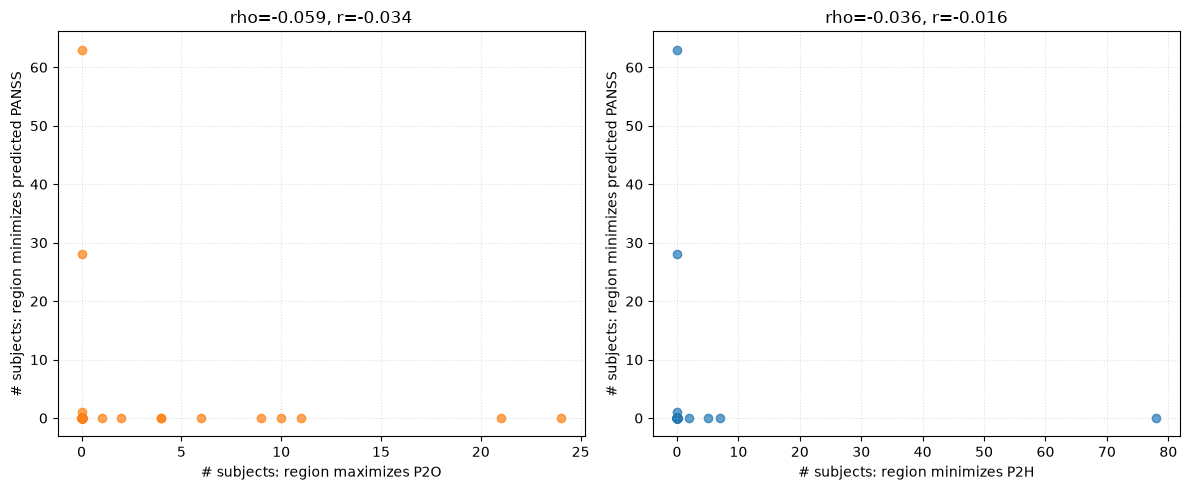

In [14]:
rho_panss_p2o, p_panss_p2o = spearmanr(counts_panss, counts_p2o)
rho_panss_p2h, p_panss_p2h = spearmanr(counts_panss, counts_p2h)
rho_p2o_p2h, p_p2o_p2h = spearmanr(counts_p2o, counts_p2h)

r_panss_p2o, pr_panss_p2o = pearsonr(counts_panss, counts_p2o)
r_panss_p2h, pr_panss_p2h = pearsonr(counts_panss, counts_p2h)
r_p2o_p2h, pr_p2o_p2h = pearsonr(counts_p2o, counts_p2h)

print("Correlation between per-region counts:")
print(f"  panss-min vs p2o-max: rho={rho_panss_p2o:+.4f} (p={p_panss_p2o:.3g})   r={r_panss_p2o:+.4f} (p={pr_panss_p2o:.3g})")
print(f"  panss-min vs p2h-min: rho={rho_panss_p2h:+.4f} (p={p_panss_p2h:.3g})   r={r_panss_p2h:+.4f} (p={pr_panss_p2h:.3g})")
print(f"  p2o-max   vs p2h-min: rho={rho_p2o_p2h:+.4f} (p={p_p2o_p2h:.3g})   r={r_p2o_p2h:+.4f} (p={pr_p2o_p2h:.3g})")


def top_k_set(counts, k=10):
    """Up to k regions with count > 0, ranked by count -- never pads with zero-count regions."""
    order = np.argsort(counts)[::-1]
    nonzero = [int(r) for r in order if counts[r] > 0]
    return set(nonzero[:k])


def jaccard(set_a, set_b):
    return len(set_a & set_b) / len(set_a | set_b)


K = 10
top_panss, top_p2o, top_p2h = top_k_set(counts_panss, K), top_k_set(counts_p2o, K), top_k_set(counts_p2h, K)
print(f"\n(Note: {len(top_panss)}/{K}, {len(top_p2o)}/{K}, {len(top_p2h)}/{K} slots filled for "
      f"panss-min/p2o-max/p2h-min respectively -- fewer than K means that few regions ever won at all.)")

print(f"\nTop-{K} region overlap (Jaccard, zero-count regions excluded):")
print(f"  panss-min vs p2o-max: {jaccard(top_panss, top_p2o):.3f}  (shared: {sorted(top_panss & top_p2o)})")
print(f"  panss-min vs p2h-min: {jaccard(top_panss, top_p2h):.3f}  (shared: {sorted(top_panss & top_p2h)})")
print(f"  p2o-max   vs p2h-min: {jaccard(top_p2o, top_p2h):.3f}  (shared: {sorted(top_p2o & top_p2h)})")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(counts_p2o, counts_panss, color='#ff7f0e', alpha=0.7)
axes[0].set_xlabel('# subjects: region maximizes P2O')
axes[0].set_ylabel('# subjects: region minimizes predicted PANSS')
axes[0].set_title(f'rho={rho_panss_p2o:.3f}, r={r_panss_p2o:.3f}')
axes[0].grid(True, linestyle=':', alpha=0.4)

axes[1].scatter(counts_p2h, counts_panss, color='#1f77b4', alpha=0.7)
axes[1].set_xlabel('# subjects: region minimizes P2H')
axes[1].set_ylabel('# subjects: region minimizes predicted PANSS')
axes[1].set_title(f'rho={rho_panss_p2h:.3f}, r={r_panss_p2h:.3f}')
axes[1].grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

## Notes

- **The strict hypothesis (exact-argmin match) is not supported**: across all 92
  subjects, the node that minimizes predicted PANSS under perturbation is never the
  same node that minimizes P2H (match rate 0/92, vs. 1/100 expected by chance).
- **A much weaker, but statistically real, version of the hypothesis does hold for
  P2H**: the P2H-minimizing node's rank within a subject's ascending predicted-PANSS
  ordering is significantly better than chance (mean rank ~45 vs. null 50.5,
  `p ~ 0.003`), and the per-subject Spearman correlation between the full `node_preds`
  and `p2h` curves is small but consistently positive (`mean rho ~ 0.05`). The P2H-
  favored perturbation tends to look *somewhat* better to the PANSS model than a random
  node, but far from "the same optimum."
- **P2O shows the opposite (weakly negative) within-subject relationship** with
  predicted PANSS (`mean per-subject rho ~ -0.16`), while its rank-position effect is
  not significant on its own (`p ~ 0.56`) -- consistent with the previously documented
  P2H/P2O anticorrelation (see `output_study.ipynb`), rather than an independent effect.
- **Pooled correlations (raw, across all subject-node pairs)** run opposite in sign to
  the within-subject per-subject correlations above (`corr(node_preds, p2h) = -0.25`,
  `corr(node_preds, p2o) = +0.26`). Since this pools between-subject differences
  (sicker subjects tend to differ from milder ones on both axes) together with the
  node-to-node differences the hypothesis is about, the per-subject Spearman analysis
  above -- not these pooled numbers -- is the relevant read of the "same perturbation"
  hypothesis.
- **Cohort-level region concentration is extreme, and the winning regions barely
  overlap across lists.** Only **3** distinct regions are *ever* the PANSS-minimizing
  node across all 92 subjects (region 63 alone wins for 63/92 = 68%, region 29 for
  28/92), and only **4** distinct regions are ever the P2H-minimizing node (region 26
  alone wins for 78/92 = 85%). P2O is comparatively more spread (10 distinct regions
  win at least once), still dominated by two (regions 8 and 36, 24 and 21 wins). Despite
  each list being individually so concentrated, the PANSS-minimizing set shares **zero**
  regions with either perturbability list (Jaccard = 0 for both), while P2O's and P2H's
  own top sets overlap modestly (Jaccard = 0.167, shared regions 26 and 69) -- consistent
  with P2O and P2H measuring related "perturbability magnitude" phenomena that are
  distinct from what the fixed PANSS model favors.
- **Caveat on over-reading region 63/26 as a neurobiological finding:** `node_preds` is
  a *linear* (Ridge) readout of a fixed feature set, and the same fitted weight vector
  (up to leave-one-out retraining, which barely moves it) is applied to every subject.
  A single region dominating 60-85% of subjects' "best perturbation" is therefore at
  least partly a signature of the model being linear and subject-invariant, not
  necessarily proof that region 63 (or 26) is uniquely important biologically --
  perturbing it happens to shift the fixed selected Ftau features in a consistently
  favorable (or unfavorable, for P2H) direction for most subjects under *this* model.
  Whether it survives under a different feature-selection threshold or regressor is an
  open question this notebook doesn't address.
- Recall the **delta_sigma=0.1 assumption for P2O** (intro caveat) -- P2O's generating
  code could not be recovered from the repo, so its comparisons here should be read as
  approximate.